# Linear Regression (with `statsmodels`)

This notebook will teach you how to estimate Ordinary Least Squares (OLS)
regression models and run hypothesis tests on their coefficients using
`statsmodels`.

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import statsmodels.api as sm

URL = 'https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/master/csv/wooldridge/wage1.csv'

## Simple Linear Regression

We'll use Wooldridge's classic Mincer earnings dataset (`wage1.csv`), which
contains wages, schooling, and experience for 526 U.S. workers.

In [3]:
cols = [
    'wage', 'lwage', 'educ', 'exper', 'expersq', 'tenure', 'female',
    'married', 'nonwhite',
]
df = pd.read_csv(URL)[cols]
display(df.head())

,wage,lwage,educ,exper,expersq,tenure,female,married,nonwhite
0,3.10,1.131402,11,2,4,0,1,0,0
1,3.24,1.175573,12,22,484,2,1,1,0
2,3.00,1.098612,11,2,4,0,0,0,0
3,6.00,1.791759,8,44,1936,28,0,1,0
4,5.30,1.667707,12,7,49,2,0,1,0


Let's start with a simple regression model of log hourly wages (`lwage`) on
years of education (`educ`):

$$\log(\text{wage}_i) = \beta_0 + \beta_1 \text{educ}_i + u_i$$

**NOTE:** `statsmodels` does *not* include an intercept ($\beta_0$) by
default. We have to add a column of `1`s to our design matrix $X$.

Remember that `df['educ']` is a 1D Series, which cannot hold multiple
columns. Instead, we slice it as a DataFrame using `df[['educ']].copy()` and
manually assign `X_simple['const'] = 1`.

In [4]:
y = df['lwage']
X_simple = df[['educ']].copy()  # Not df['educ'] because this would be a Series
X_simple['const'] = 1
display(X_simple.head())

,educ,const
0,11,1
1,12,1
2,11,1
3,8,1
4,12,1


Now we instantiate an `OLS` model object (remember classes from the first
notebook?) and call its `.fit()` method to estimate the parameters.

In [5]:
model_simple = sm.OLS(y, X_simple)  # Init theoretical model
results_simple = model_simple.fit()  # Fit that theoretical model to the data
print(results_simple.summary())

                            OLS Regression Results                            
Dep. Variable:                  lwage   R-squared:                       0.186
Model:                            OLS   Adj. R-squared:                  0.184
Method:                 Least Squares   F-statistic:                     119.6
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           3.27e-25
Time:                        14:35:48   Log-Likelihood:                -359.38
No. Observations:                 526   AIC:                             722.8
Df Residuals:                     524   BIC:                             731.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
educ           0.0827      0.008     10.935      0.0

> Each additional year of schooling is associated with an ~8.27% increase in
hourly wages.

Instead of reading numbers off the summary table, we can grab estimated
attributes directly from the `results_simple` object:

In [6]:
print('Coefficients:\n', results_simple.params, sep='')
print('\nStandard errors\n:', results_simple.bse, sep='')
print('\nR-squared:', round(results_simple.rsquared, 4))

Coefficients:
educ     0.082744
const    0.583773
dtype: float64

Standard errors
:educ     0.007567
const    0.097336
dtype: float64

R-squared: 0.1858


### Visualizing the Fitted Line

`results_simple.fittedvalues` gives us the predicted values
$\hat{y}_i = \hat{\beta}_0 + \hat{\beta}_1 \text{educ}_i$ for every worker.
Let's plot them over the raw data.

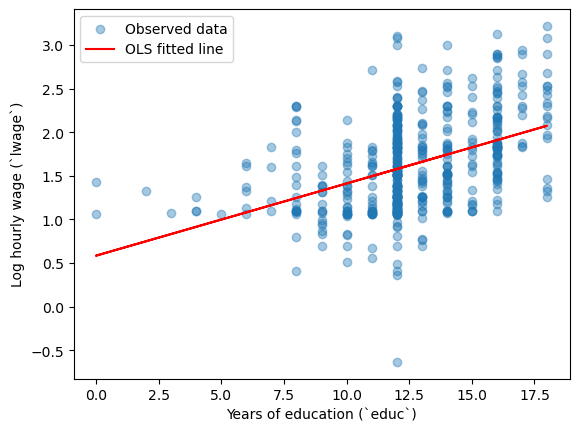

In [7]:
plt.scatter(df['educ'], y, alpha=0.4, label='Observed data')
plt.plot(
    df['educ'],
    results_simple.fittedvalues,
    color='red',
    label='OLS fitted line',
)
plt.xlabel('Years of education (`educ`)')
plt.ylabel('Log hourly wage (`lwage`)')
plt.legend()
plt.show()

## Multiple Linear Regression (The Mincer Equation)

Education isn't the only thing driving wages! Let's estimate the full Mincer
earnings equation by passing a list of columns into `X`:

$$
\log(\text{wage}_i) = \beta_0 + \beta_1 \text{educ}_i + \beta_2 \text{exper}_i
    + \beta_3 \text{exper}_i^2 + \beta_4 \text{tenure}_i
    + \beta_5 \text{female}_i + u_i
$$

In [13]:
features = ['educ', 'exper', 'expersq', 'tenure', 'female']
X_mincer = df[features].copy()
X_mincer['const'] = 1
mincer_model = sm.OLS(y, X_mincer)
mincer_results = mincer_model.fit()
print(mincer_results.summary())

                            OLS Regression Results                            
Dep. Variable:                  lwage   R-squared:                       0.434
Model:                            OLS   Adj. R-squared:                  0.429
Method:                 Least Squares   F-statistic:                     79.77
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           4.78e-62
Time:                        14:37:00   Log-Likelihood:                -263.72
No. Observations:                 526   AIC:                             539.4
Df Residuals:                     520   BIC:                             565.0
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
educ           0.0810      0.007     11.934      0.0

Try to estimate an expanded Mincer model that also includes `married` and
`nonwhite` as controls, and print its summary.

In [ ]:
# Your code here

## $t$-Tests on Coefficients

A $t$-test evaluates a **single linear restriction** on the coefficients.

### Default $t$-Tests ($H_0: \beta_k = 0$)

The `t` and `P>|t|` columns in `.summary()` automatically test whether each
coefficient is equal to zero ($t = \hat{\beta}_k / \text{SE}(\hat{\beta}_k)$).
We can also access them directly:

In [16]:
print('t-statistics:\n', mincer_results.tvalues, sep='')
print('\np-values:\n', mincer_results.pvalues, sep='')

t-statistics:
educ       11.933544
exper       6.819579
expersq    -6.197377
tenure      5.628608
female     -8.279736
const       4.170576
dtype: float64

p-values:
educ       3.487451e-29
exper      2.542656e-11
expersq    1.169315e-09
tenure     2.974312e-08
female     1.049372e-15
const      3.559832e-05
dtype: float64


### Testing Against a Specific Value ($H_0: \beta_k = c$)

What if our null hypothesis isn't zero? Use `.t_test()` with a string
expression. For example, let's test whether the return to an extra year of
education is equal to 10% ($H_0: \beta_{\text{educ}} = 0.10$):

In [17]:
# Test H0: educ = 0.10
print(mincer_results.t_test('educ = 0.10'))

                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0             0.0810      0.007     -2.807      0.005       0.068       0.094


Since $p = 0.005 < 0.05$, we reject the null that the return to schooling is
10%.

### Testing Equality of Two Coefficients ($H_0: \beta_j = \beta_k$)

Does an extra year of formal schooling (`educ`) yield the same return as an
extra year of tenure with the current employer (`tenure`)? We can pass
`'educ = tenure'` directly to `.t_test()`:

In [18]:
# Test H0: educ - tenure = 0
print(mincer_results.t_test('educ = tenure'))

                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0             0.0647      0.008      8.533      0.000       0.050       0.080


Try to use `.t_test()` on `mincer` to test whether the gender wage penalty
(`female`) is equal to $-0.25$ ($H_0: \beta_{\text{female}} = -0.25$).

In [ ]:
# Your code here

In [21]:
print(mincer_results.t_test('female = 0'))

                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0            -0.2979      0.036     -8.280      0.000      -0.369      -0.227


## $F$-Tests (Joint Hypothesis Tests)

Use an $F$-test when you want to test **multiple restrictions at the same
time**.

### Overall Model Significance

The `F-statistic` at the top right of `.summary()` tests whether *all* slope
coefficients are jointly zero
($H_0: \beta_{\text{educ}} = \beta_{\text{exper}} = \beta_{\text{expersq}}
= \beta_{\text{tenure}} = \beta_{\text{female}} = 0$).

In [22]:
print('Overall F-stat:', mincer_results.fvalue)
print('Overall F p-value:', mincer_results.f_pvalue)

Overall F-stat: 79.76826102669088
Overall F p-value: 4.784912064373753e-62


### Joint Significance of a Subset of Variables

In our Mincer model, experience enters as a quadratic (`exper` and `expersq`).
To test whether experience matters *overall*, we can't just look at one
$t$-stat—we have to test both coefficients jointly
($H_0: \beta_{\text{exper}} = 0 \text{ and } \beta_{\text{expersq}} = 0$) using
`.f_test()`:

In [23]:
# Separate multiple restrictions with a comma
print(mincer_results.f_test('exper = 0, expersq = 0'))

<F test: F=23.541591235577673, p=1.6319606267148258e-10, df_denom=520, df_num=2>


### Connecting $t$ and $F$ ($F = t^2$)

When testing just **one** restriction, an $F$-test is identical to a two-sided
$t$-test: the $F$-statistic is simply the $t$-statistic squared ($F = t^2$),
and their $p$-values match!

In [24]:
t_res = mincer_results.t_test('educ = tenure')
f_res = mincer_results.f_test('educ = tenure')

print('t-stat squared:', (t_res.tvalue.item() ** 2))
print('F-stat:        ', f_res.fvalue)

t-stat squared: 72.80360829889287
F-stat:         72.80360829889287


Try to run an $F$-test on `mincer` for the joint hypothesis that neither
workplace experience nor job tenure has any effect on wages
($H_0: \beta_{\text{exper}} = 0, \beta_{\text{expersq}} = 0,
\beta_{\text{tenure}} = 0$).

In [ ]:
# Your code here